### Notebook 1: Data exploration
Pork Rasher Error(Packaging) dataset, Roboflow version 4 (YOLOv11 format).

#### 0. Setup

In [2]:
# Mount Google Drive and unzip the dataset
import zipfile
from pathlib import Path

ZIP_PATH = Path("/content/drive/MyDrive/pork_rasher_v4.zip")
DATA_DIR = Path("/content/pork_rasher")
# DATA_DIR = Path(r"C:\Users\you\Downloads\pork_rasher")   # local path (if not using Colab)

try:
    from google.colab import drive
    drive.mount("/content/drive")
    if not (DATA_DIR / "data.yaml").exists():   # unzip if not already done
        zipfile.ZipFile(ZIP_PATH).extractall(DATA_DIR)
except ImportError:
    pass   # not running on Colab

assert (DATA_DIR / "data.yaml").exists(), "can't find data.yaml, check the zip name and where it is"
print("data folder:", DATA_DIR)

Mounted at /content/drive
data folder: /content/pork_rasher


In [3]:
# Imports
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import yaml
from PIL import Image

SPLITS = ["train", "valid", "test"]

#### 1. Class names

In [4]:
# Read class names from data.yaml
with open(DATA_DIR / "data.yaml") as f:
    CLASS_NAMES = yaml.safe_load(f)["names"]

for i, name in enumerate(CLASS_NAMES):
    print(i, name)

0 loose-meat
1 packaging-error
2 twisted-meat
3 unsealed
4 wrinkle


#### 2. Load labels

In [5]:
# Read every image and label file into two tables (one row per image, one row per box)
image_rows = []
box_rows = []

for split in SPLITS:
    img_files = sorted(p for p in (DATA_DIR / split / "images").iterdir()
                       if p.suffix.lower() in [".jpg", ".jpeg", ".png"])
    for img_path in img_files:
        label_path = DATA_DIR / split / "labels" / (img_path.stem + ".txt")
        lines = label_path.read_text().splitlines() if label_path.exists() else []

        n_boxes = 0
        for line in lines:
            parts = line.split()
            if len(parts) != 5:   # skip blank or invalid lines
                continue
            cls = int(parts[0])
            xc, yc, w, h = [float(v) for v in parts[1:]]
            box_rows.append({"split": split, "image": img_path.name, "class_id": cls,
                             "class_name": CLASS_NAMES[cls], "xc": xc, "yc": yc, "w": w, "h": h})
            n_boxes += 1

        frame = re.search(r"frame_with_red_(\d+)", img_path.name)
        image_rows.append({"split": split, "image": img_path.name, "path": str(img_path),
                           "n_boxes": n_boxes,
                           "source_stem": img_path.name.split(".rf.")[0],
                           "frame_no": int(frame.group(1)) if frame else None})

images = pd.DataFrame(image_rows)
boxes = pd.DataFrame(box_rows)
print(len(images), "images,", len(boxes), "boxes")
images.head()

3549 images, 3123 boxes


,split,image,path,n_boxes,source_stem,frame_no
0,train,frame_with_red_10049_jpg.rf.cd786c4f9dd783e72b...,/content/pork_rasher/train/images/frame_with_r...,1,frame_with_red_10049_jpg,10049
1,train,frame_with_red_10049_jpg.rf.d742c71486ef35ee0d...,/content/pork_rasher/train/images/frame_with_r...,1,frame_with_red_10049_jpg,10049
2,train,frame_with_red_10049_jpg.rf.debe2aadb81b4c3985...,/content/pork_rasher/train/images/frame_with_r...,1,frame_with_red_10049_jpg,10049
3,train,frame_with_red_10050_jpg.rf.9c1d242a09e36de1f7...,/content/pork_rasher/train/images/frame_with_r...,1,frame_with_red_10050_jpg,10050
4,train,frame_with_red_10050_jpg.rf.d9a41729948289ba87...,/content/pork_rasher/train/images/frame_with_r...,1,frame_with_red_10050_jpg,10050


#### 3. Images and boxes per split

In [6]:
# Image, unique image, box and no-defect image counts per split
summary = images.groupby("split").agg(images=("image", "count"),
                                      unique_source_images=("source_stem", "nunique"),
                                      boxes=("n_boxes", "sum"))
summary["images_with_no_boxes"] = images[images.n_boxes == 0].groupby("split").size()
summary = summary.reindex(SPLITS).fillna(0).astype(int)
summary

,images,unique_source_images,boxes,images_with_no_boxes
split,,,,
train,3349,1085,2923,684
valid,120,120,121,14
test,80,80,79,12


#### 4. Boxes per class

boxes per class:
split            train  valid  test
class_name                         
loose-meat          66      3     3
packaging-error   1712     34    23
twisted-meat        72      3     4
unsealed          1055     81    49
wrinkle             18      0     0 

images containing each class:
split            train  valid  test
class_name                         
loose-meat          66      3     2
packaging-error   1541     23    16
twisted-meat        69      3     4
unsealed          1055     81    49
wrinkle             18      0     0


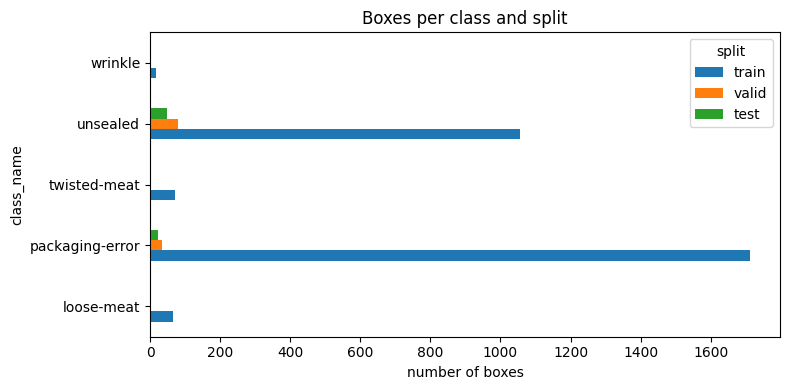

In [7]:
# Box and image counts per class and split
box_counts = pd.crosstab(boxes.class_name, boxes.split).reindex(index=CLASS_NAMES, columns=SPLITS, fill_value=0)

# images containing each class (each image counted once per class)
one_per_image = boxes.drop_duplicates(["split", "image", "class_name"])
img_counts = pd.crosstab(one_per_image.class_name, one_per_image.split).reindex(index=CLASS_NAMES, columns=SPLITS, fill_value=0)

print("boxes per class:")
print(box_counts, "\n")
print("images containing each class:")
print(img_counts)

box_counts.plot(kind="barh", figsize=(8, 4), title="Boxes per class and split")
plt.xlabel("number of boxes")
plt.tight_layout()
plt.show()

#### 5. Class co-occurrence

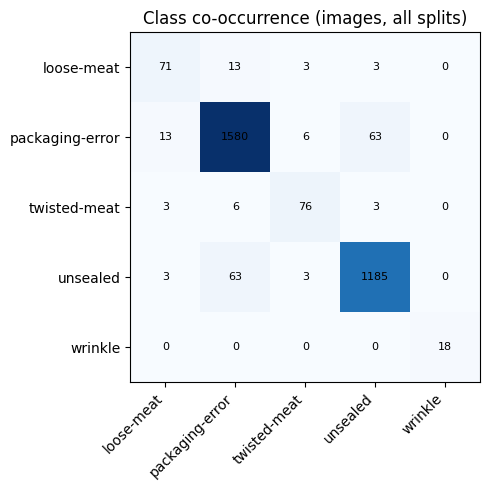

images with packaging-error: 1580
  of those, no other class: 1498


In [8]:
# Number of images containing each pair of classes
# 1 if the image has the class, 0 if not
presence = pd.crosstab([boxes.split, boxes.image], boxes.class_name).clip(upper=1)
presence = presence.reindex(columns=CLASS_NAMES, fill_value=0)
together = presence.T @ presence   # images containing both classes

fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(together.values, cmap="Blues")
ax.set_xticks(range(len(CLASS_NAMES)), CLASS_NAMES, rotation=45, ha="right")
ax.set_yticks(range(len(CLASS_NAMES)), CLASS_NAMES)
for i in range(len(CLASS_NAMES)):
    for j in range(len(CLASS_NAMES)):
        ax.text(j, i, together.values[i, j], ha="center", va="center", fontsize=8)
ax.set_title("Class co-occurrence (images, all splits)")
plt.tight_layout()
plt.show()

pe = presence["packaging-error"] == 1
pe_alone = pe & (presence.drop(columns="packaging-error").sum(axis=1) == 0)
print("images with packaging-error:", pe.sum())
print("  of those, no other class:", pe_alone.sum())

In [9]:
# packaging-error / unsealed overlap per split
for split in SPLITS:
    p = presence.loc[split]
    pe = p["packaging-error"] == 1
    both = pe & (p["unsealed"] == 1)
    print(f"{split}: {pe.sum()} images with packaging-error, {both.sum()} of them also have unsealed")

train: 1541 images with packaging-error, 57 of them also have unsealed
valid: 23 images with packaging-error, 3 of them also have unsealed
test: 16 images with packaging-error, 3 of them also have unsealed


#### 6. Box sizes

                  count    mean     std     min     25%     50%     75%  \
class_name                                                                
loose-meat         72.0  0.0543  0.0341  0.0088  0.0306  0.0543  0.0688   
packaging-error  1769.0  0.0109  0.0170  0.0004  0.0026  0.0037  0.0090   
twisted-meat       79.0  0.0414  0.0184  0.0108  0.0321  0.0382  0.0526   
unsealed         1185.0  0.1119  0.0541  0.0042  0.0794  0.1086  0.1387   
wrinkle            18.0  0.0111  0.0070  0.0035  0.0064  0.0095  0.0124   

                    max  
class_name               
loose-meat       0.1456  
packaging-error  0.1270  
twisted-meat     0.1013  
unsealed         0.3025  
wrinkle          0.0249  


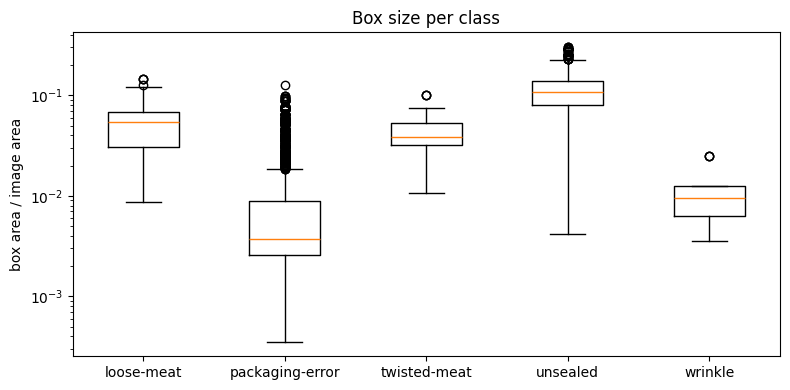

In [10]:
# Box area as a fraction of the image, per class
boxes["area"] = boxes.w * boxes.h
print(boxes.groupby("class_name")["area"].describe().reindex(CLASS_NAMES).round(4))

data = [boxes[boxes.class_name == c].area for c in CLASS_NAMES]
plt.figure(figsize=(8, 4))
plt.boxplot(data)
plt.xticks(range(1, len(CLASS_NAMES) + 1), CLASS_NAMES)
plt.yscale("log")
plt.ylabel("box area / image area")
plt.title("Box size per class")
plt.tight_layout()
plt.show()

#### 7. Images with boxes

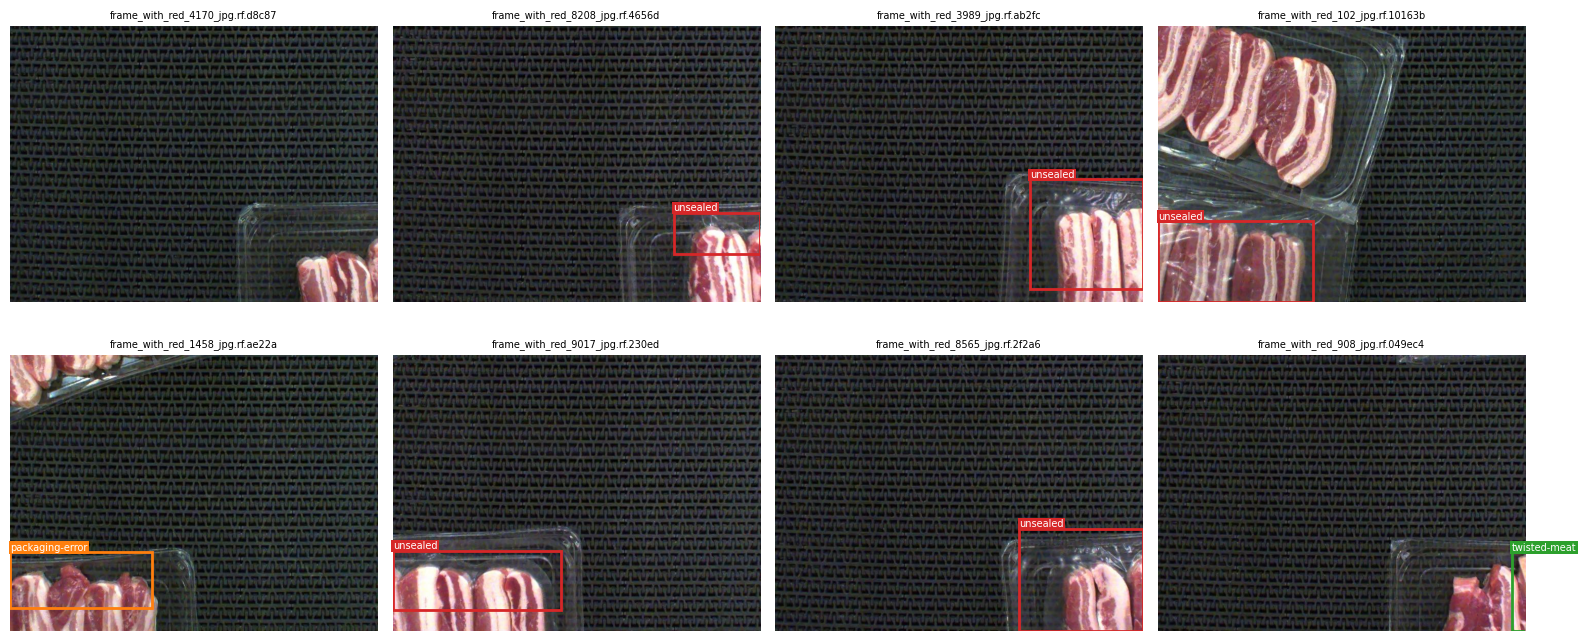

In [11]:
# Show random images with their labelled boxes
CLASS_TO_SHOW = None    # class to filter by, or None for all
SPLIT_TO_SHOW = "test"  # split to sample from


def show_image(path, ax):
    img = Image.open(path)
    W, H = img.size
    ax.imshow(img)
    for _, b in boxes[boxes.image == Path(path).name].iterrows():
        # normalised centre/size -> pixel corner
        x0 = (b.xc - b.w / 2) * W
        y0 = (b.yc - b.h / 2) * H
        colour = plt.cm.tab10(b.class_id)
        ax.add_patch(patches.Rectangle((x0, y0), b.w * W, b.h * H, fill=False, lw=2, ec=colour))
        ax.text(x0, y0 - 3, b.class_name, color="white", fontsize=7, bbox=dict(fc=colour, ec="none", pad=1))
    ax.set_title(Path(path).name[:32], fontsize=7)
    ax.axis("off")


pool = images[images.split == SPLIT_TO_SHOW]
if CLASS_TO_SHOW:
    pool = pool[pool.image.isin(boxes[boxes.class_name == CLASS_TO_SHOW].image)]
sample = pool.sample(min(8, len(pool)))

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax in axes.flat:
    ax.axis("off")
for ax, path in zip(axes.flat, sample.path):
    show_image(path, ax)
plt.tight_layout()
plt.show()

#### 8. Leakage check

##### Check 1: original images in more than one split

In [12]:
# Count original images that appear in more than one split
splits_per_image = images.groupby("source_stem").split.nunique()
print("original images in more than one split:", (splits_per_image > 1).sum())

original images in more than one split: 13


##### Check 2: frame gap to nearest training frame

valid: 120 frames | median gap 3 | within 5 frames: 67.5% | within 1 frame: 22.5%
test: 80 frames | median gap 2 | within 5 frames: 67.5% | within 1 frame: 28.7%


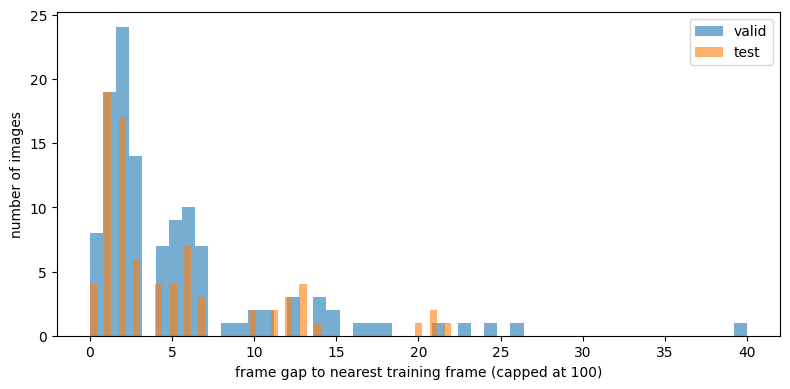

In [13]:
# Frame-number gap from each valid/test image to the nearest training frame
train_frames = images[images.split == "train"].frame_no.dropna().unique()

plt.figure(figsize=(8, 4))
for split in ["valid", "test"]:
    frames = images[images.split == split].frame_no.dropna().unique()
    gaps = np.array([np.abs(train_frames - f).min() for f in frames])
    print(f"{split}: {len(gaps)} frames | median gap {np.median(gaps):.0f} | "
          f"within 5 frames: {np.mean(gaps <= 5) * 100:.1f}% | within 1 frame: {np.mean(gaps <= 1) * 100:.1f}%")
    plt.hist(np.clip(gaps, 0, 100), bins=50, alpha=0.6, label=split)
plt.xlabel("frame gap to nearest training frame (capped at 100)")
plt.ylabel("number of images")
plt.legend()
plt.tight_layout()
plt.show()

##### Check 3: image similarity (difference hash)

hashing 1085 training images...
valid: median distance 4 | <=5 bits: 75.8% | <=10 bits: 99.2%
test: median distance 4 | <=5 bits: 75.0% | <=10 bits: 98.8%


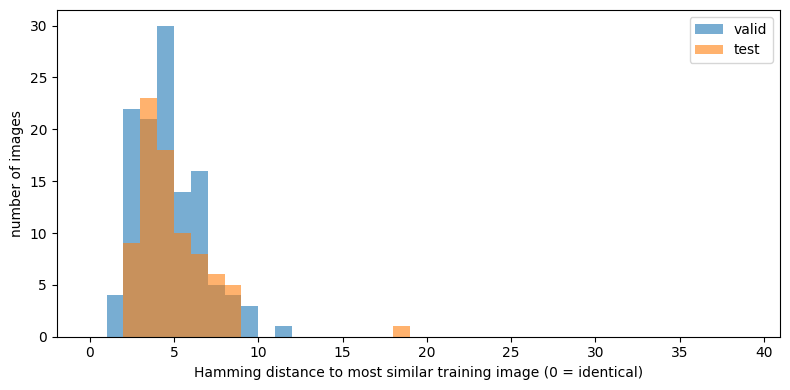

In [14]:
# 64-bit difference hash per image, and Hamming distance to the most similar training image
def dhash(path):
    grey = np.array(Image.open(path).convert("L").resize((9, 8)), dtype=int)
    bits = (grey[:, 1:] > grey[:, :-1]).flatten()
    return int("".join("1" if b else "0" for b in bits), 2)


def hamming(a, b):
    return bin(a ^ b).count("1")   # number of differing bits


train_unique = images[images.split == "train"].drop_duplicates("source_stem")
print("hashing", len(train_unique), "training images...")
train_hashes = [dhash(p) for p in train_unique.path]

plt.figure(figsize=(8, 4))
for split in ["valid", "test"]:
    dists = []
    for p in images[images.split == split].path:
        h = dhash(p)
        dists.append(min(hamming(h, t) for t in train_hashes))
    dists = np.array(dists)
    print(f"{split}: median distance {np.median(dists):.0f} | <=5 bits: {np.mean(dists <= 5) * 100:.1f}% | "
          f"<=10 bits: {np.mean(dists <= 10) * 100:.1f}%")
    plt.hist(dists, bins=range(0, 40), alpha=0.6, label=split)
plt.xlabel("Hamming distance to most similar training image (0 = identical)")
plt.ylabel("number of images")
plt.legend()
plt.tight_layout()
plt.show()